In [3]:
import sys, torch
import pandas as pd
import tensorflow as tf

print("Python version:", sys.version)
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

print("Available GPUs:", tf.config.list_physical_devices('GPU'))
!nvidia-smi

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
2.14.1+cpu None False
no GPU
Available GPUs: []
/bin/bash: line 1: nvidia-smi: command not found


In [4]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://www.kaggle.com/code/briscdataset/getting-started-with-brisc-2025
# Author: Amirreza Fateh, Yasin Rezvani, Sara Moayedi, Sadjad Rezvani, Fatemeh Fateh, Mansoor Fateh & Vahid Abolghasemi
# License: Apache 2.0 open source license.
# ==========================================
import os
import kagglehub

# Download latest version
BASE_DIR = kagglehub.dataset_download("briscdataset/brisc2025")
SEED = 42 # same seed as in
print("Path to dataset files:", BASE_DIR)



Using Colab cache for faster access to the 'brisc2025' dataset.
Path to dataset files: /kaggle/input/brisc2025


In [5]:
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
import importlib

sys.path.append('/content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets')
import helpers


importlib.reload(helpers)

from helpers import walk_dir, load_parsed_datasets

walk_dir(BASE_DIR, max_depth=3)

brisc2025/
  brisc2025/
  brisc2025/
    segmentation_task/
    classification_task/
    segmentation_task/
      test/
      train/
      test/
        images/
        masks/
      train/
        images/
        masks/
    classification_task/
      test/
      train/
      test/
        pituitary/
        no_tumor/
        meningioma/
        glioma/
      train/
        pituitary/
        no_tumor/
        meningioma/
        glioma/


## Parse Classification Dataset

In [7]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from:https://www.kaggle.com/code/abdallahwagih/brain-tumor-detection#Data-Preprocessing
# Author: Abdallah Wagih Ibrahim
# License: Apache 2.0 open source license.
# Adapted: Altered code to fit BRISC tree structure with LLM help (Gemini)
# ==========================================

# Generate data paths with labels
filepaths = []
labels = []

folds = os.listdir(BASE_DIR)
for fold in folds:
    foldpath = os.path.join(BASE_DIR, fold)
    filelist = os.listdir(foldpath)
    for file in filelist:
        fpath = os.path.join(foldpath, file)

        filepaths.append(fpath)
        labels.append(fold)

# Concatenate data paths with labels into one dataframe
Fseries = pd.Series(filepaths, name= 'filepaths')
Lseries = pd.Series(labels, name='labels')
df = pd.concat([Fseries, Lseries], axis= 1)

In [8]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from:https://www.kaggle.com/code/abdallahwagih/brain-tumor-detection#Data-Preprocessing
# Author: Abdallah Wagih Ibrahim
# License: Apache 2.0 open source license.
# Adapted: Altered code to fit BRISC tree structure with LLM help (Gemini)
# ==========================================

###############################
# TRAINING DATA
###############################

# Define the base directory for classification train
classification_train_dir = os.path.join(BASE_DIR, "brisc2025", "classification_task", "train")

filepaths = []
labels = []

# Check if directory exists
if os.path.exists(classification_train_dir):
    # Iterate through each class folder (glioma, pituitary, meningioma, no_tumor)
    classes = sorted(os.listdir(classification_train_dir))
    for class_name in classes:
        class_dir = os.path.join(classification_train_dir, class_name)
        if os.path.isdir(class_dir):
            for file in os.listdir(class_dir):
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    filepaths.append(os.path.join(class_dir, file))
                    labels.append(class_name)

# Create classification dataframe
classification_df = pd.DataFrame({
    'filepaths': filepaths,
    'labels': labels
})

print(f"Loaded {len(classification_df)} training images for Classification Task.")
display(classification_df.head())
print("\nTraining Class distributions:\n", classification_df['labels'].value_counts())


###############################
# TEST DATA
###############################
# Define the base directory for classification test
classification_test_dir = os.path.join(BASE_DIR, "brisc2025", "classification_task", "test")

test_filepaths = []
test_labels = []

if os.path.exists(classification_test_dir):
    classes = sorted(os.listdir(classification_test_dir))
    for class_name in classes:
        class_dir = os.path.join(classification_test_dir, class_name)
        if os.path.isdir(class_dir):
            for file in os.listdir(class_dir):
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    test_filepaths.append(os.path.join(class_dir, file))
                    test_labels.append(class_name)

# Create classification test dataframe
classification_test_df = pd.DataFrame({
    'filepaths': test_filepaths,
    'labels': test_labels
})

print(f"Loaded {len(classification_test_df)} test images for Classification Task.")
display(classification_test_df.head())
print("\nTest Class distributions:\n", classification_test_df['labels'].value_counts())


Loaded 5000 training images for Classification Task.


,filepaths,labels
0,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
1,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
2,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
3,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
4,/kaggle/input/brisc2025/brisc2025/classificati...,glioma



Training Class distributions:
 labels
pituitary     1457
meningioma    1329
glioma        1147
no_tumor      1067
Name: count, dtype: int64
Loaded 1000 test images for Classification Task.


,filepaths,labels
0,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
1,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
2,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
3,/kaggle/input/brisc2025/brisc2025/classificati...,glioma
4,/kaggle/input/brisc2025/brisc2025/classificati...,glioma



Test Class distributions:
 labels
meningioma    306
pituitary     300
glioma        254
no_tumor      140
Name: count, dtype: int64


## Parse Segmentation Dataset

In [9]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from:https://www.kaggle.com/code/abdallahwagih/brain-tumor-detection#Data-Preprocessing
# Author: Abdallah Wagih Ibrahim
# License: Apache 2.0 open source license.
# Adapted: Altered code to fit BRISC tree structure and segmentation task
# with LLM help (Gemini)
# ==========================================

#####################################
# TRAINING / EVAL DATASETS
#####################################
# Define the base directory for segmentation train
segmentation_images_dir = os.path.join(BASE_DIR, "brisc2025", "segmentation_task", "train", "images")
segmentation_masks_dir = os.path.join(BASE_DIR, "brisc2025", "segmentation_task", "train", "masks")

image_paths = []
mask_paths = []

if os.path.exists(segmentation_images_dir):
    for file in sorted(os.listdir(segmentation_images_dir)):
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(segmentation_images_dir, file)

            # Map corresponding mask filename (often same name or similar extension)
            # We search for png or jpg matching mask files
            mask_name = file.replace(".jpg", ".png").replace(".jpeg", ".png")
            mask_path = os.path.join(segmentation_masks_dir, mask_name)

            if os.path.exists(mask_path):
                image_paths.append(img_path)
                mask_paths.append(mask_path)

segmentation_df = pd.DataFrame({
    'image_path': image_paths,
    'mask_path': mask_paths
})

print(f"Loaded {len(segmentation_df)} image-mask pairs for Segmentation Task.")
display(segmentation_df.head())

#####################################
# TESTING DATASET
#####################################

# Define the base directory for segmentation test
segmentation_test_images_dir = os.path.join(BASE_DIR, "brisc2025", "segmentation_task", "test", "images")
segmentation_test_masks_dir = os.path.join(BASE_DIR, "brisc2025", "segmentation_task", "test", "masks")

test_image_paths = []
test_mask_paths = []

if os.path.exists(segmentation_test_images_dir):
    for file in sorted(os.listdir(segmentation_test_images_dir)):
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(segmentation_test_images_dir, file)

            # Map corresponding mask filename (often same name with .png extension)
            mask_name = file.replace(".jpg", ".png").replace(".jpeg", ".png")
            mask_path = os.path.join(segmentation_test_masks_dir, mask_name)

            if os.path.exists(mask_path):
                test_image_paths.append(img_path)
                test_mask_paths.append(mask_path)

segmentation_test_df = pd.DataFrame({
    'image_path': test_image_paths,
    'mask_path': test_mask_paths
})

print(f"Loaded {len(segmentation_test_df)} test image-mask pairs for Segmentation Task.")
display(segmentation_test_df.head())

Loaded 3933 image-mask pairs for Segmentation Task.


,image_path,mask_path
0,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
1,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
2,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
3,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
4,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...


Loaded 860 test image-mask pairs for Segmentation Task.


,image_path,mask_path
0,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
1,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
2,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
3,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...
4,/kaggle/input/brisc2025/brisc2025/segmentation...,/kaggle/input/brisc2025/brisc2025/segmentation...


In [10]:
#################################
# Save datasets to directory
#################################

from google.colab import drive

drive.mount('/content/drive')

checkpoint_dir = '/content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets'

os.makedirs(checkpoint_dir, exist_ok=True)


# Define output file paths in the Google Drive directory
train_csv_path = os.path.join(checkpoint_dir, 'classification_train.csv')
test_csv_path = os.path.join(checkpoint_dir, 'classification_test.csv')
train_segmentation_csv_path = os.path.join(checkpoint_dir, 'segmentation_train.csv')
test_segmentation_csv_path = os.path.join(checkpoint_dir, 'segmentation_test.csv')

# Save DataFrames to CSV
classification_df.to_csv(train_csv_path, index=False)
classification_test_df.to_csv(test_csv_path, index=False)
segmentation_df.to_csv(train_segmentation_csv_path, index=False)
segmentation_test_df.to_csv(test_segmentation_csv_path, index=False)


print(f"Saved classification training dataset to: {train_csv_path}")
print(f"Saved classification test dataset to: {test_csv_path}")
print(f"Saved segmentation training dataset to: {train_segmentation_csv_path}")
print(f"Saved segmentation test dataset to: {test_segmentation_csv_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved classification training dataset to: /content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets/classification_train.csv
Saved classification test dataset to: /content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets/classification_test.csv
Saved segmentation training dataset to: /content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets/segmentation_train.csv
Saved segmentation test dataset to: /content/drive/MyDrive/brain_tumor_mri_BRISC_parsed_datasets/segmentation_test.csv


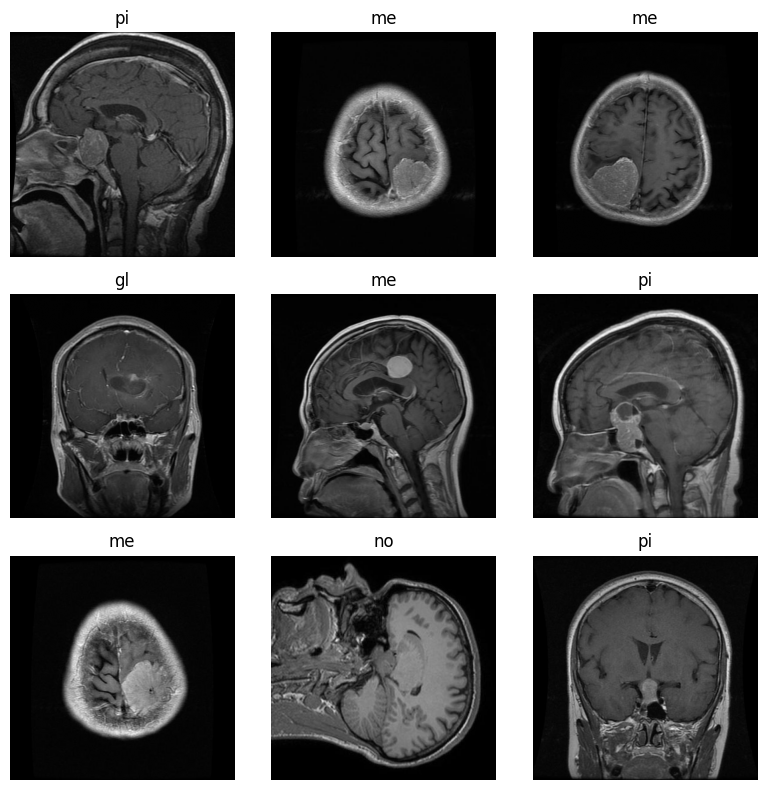

In [11]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://www.kaggle.com/code/briscdataset/getting-started-with-brisc-2025
# Author: Amirreza Fateh, Yasin Rezvani, Sara Moayedi, Sadjad Rezvani, Fatemeh Fateh, Mansoor Fateh & Vahid Abolghasemi
# License: Apache 2.0 open source license.
# ==========================================


#################################
# Show random grid of MRI scans
#################################
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Render plots inline
%matplotlib inline
# In[10] — Random Grid
samples = glob.glob(os.path.join(BASE_DIR, "brisc2025/classification_task/train/*/*.jpg"))
grid = np.random.choice(samples, 9, replace=False)

fig, axes = plt.subplots(3,3, figsize=(8,8))
axes = axes.flatten()
for ax, fp in zip(axes, grid):
    im = Image.open(fp)
    cls = os.path.basename(fp).split("_")[3]
    ax.imshow(im, cmap="gray")
    ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2990/1700249033.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(sub.Class, rotation=45)
/tmp/ipykernel_2990/1700249033.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(sub.Class, rotation=45)


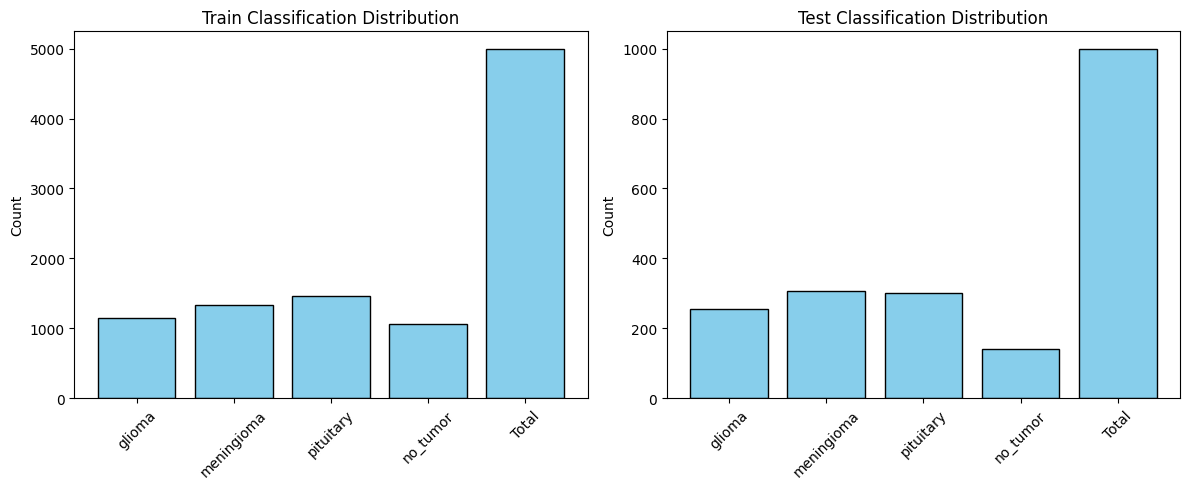

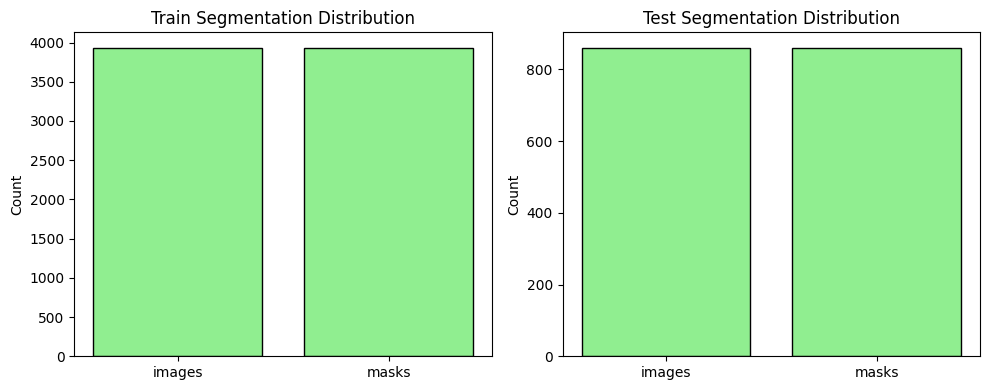

In [12]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://www.kaggle.com/code/briscdataset/getting-started-with-brisc-2025
# Author: Amirreza Fateh, Yasin Rezvani, Sara Moayedi, Sadjad Rezvani, Fatemeh Fateh, Mansoor Fateh & Vahid Abolghasemi
# License: Apache 2.0 open source license.
# Adapted with Gemini (AI Assistant) for easier rendering
# ==========================================


###############################################
# Plot distributions to see how balanced it is
###############################################

# In[4] — Distribution Plots
def count_patterns(patterns):
    return sum(len(glob.glob(p)) for p in patterns)

# Classification
splits = ["train", "test"]
classes = ["glioma", "meningioma", "pituitary", "no_tumor"]
cls_records = []
for sp in splits:
    total = 0
    for cls in classes:
        pat = os.path.join(BASE_DIR, "brisc2025/classification_task", sp, cls, "*.jpg")
        cnt = count_patterns([pat])
        cls_records.append({'Split': sp, 'Class': cls, 'Count': cnt})
        total += cnt
    cls_records.append({'Split': sp, 'Class': 'Total', 'Count': total})
df_cls = pd.DataFrame(cls_records)

types_ = ["images", "masks"]
seg_records = []
for sp in splits:
    for tp in types_:
        pats = [
            os.path.join(BASE_DIR, "brisc2025/segmentation_task", sp, tp, "*.jpg"),
            os.path.join(BASE_DIR, "brisc2025/segmentation_task", sp, tp, "*.png")
        ]
        cnt = count_patterns(pats)
        seg_records.append({'Split': sp, 'Type': tp, 'Count': cnt})
df_seg = pd.DataFrame(seg_records)

splits = ["train", "test"]
df_cls = pd.DataFrame(cls_records)
df_seg = pd.DataFrame(seg_records)

# Plot classification distributions side-by-side to avoid slider/scroller
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, sp in enumerate(splits):
    sub = df_cls[df_cls.Split == sp]
    axes[i].bar(sub.Class, sub.Count, edgecolor='k', color='skyblue')
    axes[i].set_title(f"{sp.title()} Classification Distribution")
    axes[i].set_ylabel("Count")
    axes[i].set_xticklabels(sub.Class, rotation=45)
plt.tight_layout()
plt.show()

# Plot segmentation distributions side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for i, sp in enumerate(splits):
    sub = df_seg[df_seg.Split == sp]
    axes[i].bar(sub.Type, sub.Count, edgecolor='k', color='lightgreen')
    axes[i].set_title(f"{sp.title()} Segmentation Distribution")
    axes[i].set_ylabel("Count")
plt.tight_layout()
plt.show()

In [13]:
# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://www.kaggle.com/code/briscdataset/getting-started-with-brisc-2025
# Author: Amirreza Fateh, Yasin Rezvani, Sara Moayedi, Sadjad Rezvani, Fatemeh Fateh, Mansoor Fateh & Vahid Abolghasemi
# License: Apache 2.0 open source license.
# ==========================================

###############################################
# Example of filename metadata parsing
###############################################

# In[8] — Metadata Table
meta = []
for sp in splits:
    for cls in classes:
        files = glob.glob(os.path.join(BASE_DIR, "brisc2025/classification_task", sp, cls, "*.jpg"))[:1]
        for f in files:
            parts = os.path.basename(f).split("_")
            meta.append({
                "Filename": os.path.basename(f),
                "Split": parts[1],
                "Index": parts[2],
                "Tumor": parts[3],
                "Plane": parts[4],
                "Sequence": parts[5].split(".")[0]
            })
df_meta = pd.DataFrame(meta)
print("### Sample Filename Metadata")
display(df_meta)

### Sample Filename Metadata


,Filename,Split,Index,Tumor,Plane,Sequence
0,brisc2025_train_00160_gl_ax_t1.jpg,train,00160,gl,ax,t1
1,brisc2025_train_01914_me_co_t1.jpg,train,01914,me,co,t1
2,brisc2025_train_04966_pi_sa_t1.jpg,train,04966,pi,sa,t1
3,brisc2025_train_03371_no_sa_t1.jpg,train,03371,no,sa,t1
4,brisc2025_test_00177_gl_sa_t1.jpg,test,00177,gl,sa,t1
5,brisc2025_test_00560_me_sa_t1.jpg,test,00560,me,sa,t1
6,brisc2025_test_00949_pi_sa_t1.jpg,test,00949,pi,sa,t1
7,brisc2025_test_00643_no_co_t1.jpg,test,00643,no,co,t1


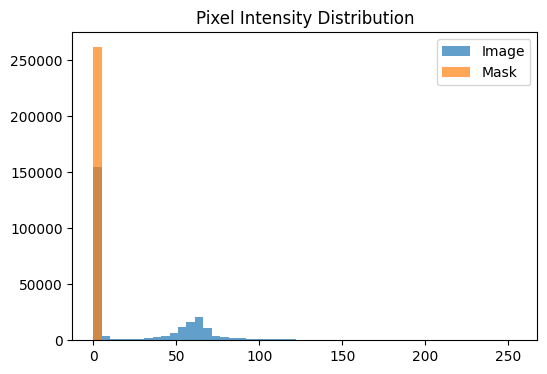

In [14]:
# In[7] — Histograms

# ==========================================
# CITATION / SOURCE ATTRIBUTION
# Original code retrieved from: https://www.kaggle.com/code/briscdataset/getting-started-with-brisc-2025
# Author: Amirreza Fateh, Yasin Rezvani, Sara Moayedi, Sadjad Rezvani, Fatemeh Fateh, Mansoor Fateh & Vahid Abolghasemi
# License: Apache 2.0 open source license.
# ==========================================

###############################################################
# Example of Glioma positive image / mask histogram comparison
###############################################################

def first_file(folder, exts):
    for ext in exts:
        fl = glob.glob(os.path.join(folder, f"*.{ext}"))
        if fl: return fl[0]
    return None

img_path  = first_file(os.path.join(BASE_DIR, "brisc2025/classification_task/train/glioma"), ["jpg"])
mask_path = first_file(os.path.join(BASE_DIR, "brisc2025/segmentation_task/train/masks"), ["png","jpg"])

img  = Image.open(img_path)
mask = Image.open(mask_path)

arr_img  = np.array(img).ravel()
arr_mask = np.array(mask).ravel()

plt.figure(figsize=(6,4))
plt.hist(arr_img,  bins=50, alpha=0.7, label="Image")
plt.hist(arr_mask, bins=50, alpha=0.7, label="Mask")
plt.legend(); plt.title("Pixel Intensity Distribution"); plt.show()